In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/processed/paddy_eda.csv",
    dtype={"year": str}
)

df.head()

,district,year,season,average_yield_kg_ha,sown_extent_ha,harvested_extent_ha,year_start
0,AMPARA,1978/1979,Maha,3124.0,44037.0,41779.0,1978
1,ANURADHAPURA,1978/1979,Maha,3528.0,75060.0,72864.0,1978
2,BADULLA,1978/1979,Maha,3091.0,16337.0,16100.0,1978
3,BATTICALOA,1978/1979,Maha,2364.0,46002.0,38896.0,1978
4,COLOMBO,1978/1979,Maha,2038.0,7270.0,7059.0,1978


In [4]:
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

df.info()

Dataset shape: (2274, 7)

Column names: ['district', 'year', 'season', 'average_yield_kg_ha', 'sown_extent_ha', 'harvested_extent_ha', 'year_start']
<class 'pandas.DataFrame'>
RangeIndex: 2274 entries, 0 to 2273
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   district             2274 non-null   str    
 1   year                 2274 non-null   str    
 2   season               2274 non-null   str    
 3   average_yield_kg_ha  2274 non-null   float64
 4   sown_extent_ha       2274 non-null   float64
 5   harvested_extent_ha  2274 non-null   float64
 6   year_start           2274 non-null   int64  
dtypes: float64(3), int64(1), str(3)
memory usage: 124.5 KB


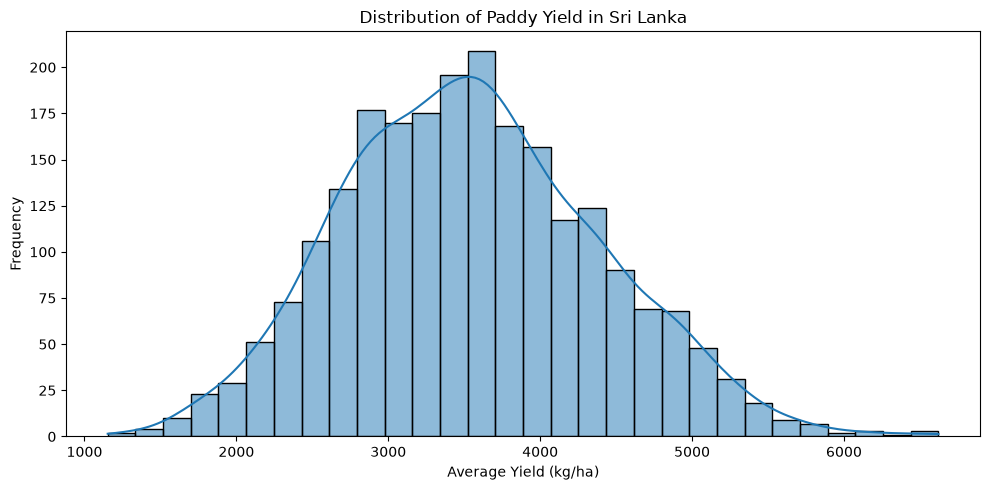

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="average_yield_kg_ha",
    bins=30,
    kde=True
)

plt.title("Distribution of Paddy Yield in Sri Lanka")
plt.xlabel("Average Yield (kg/ha)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

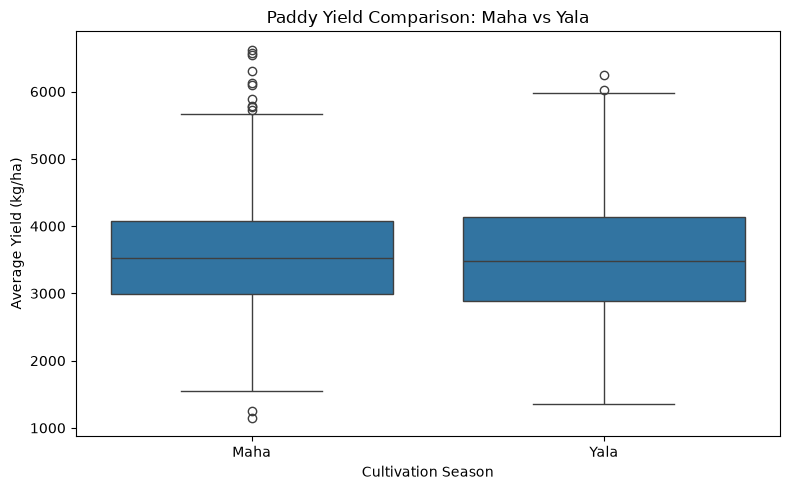

In [6]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="season",
    y="average_yield_kg_ha"
)

plt.title("Paddy Yield Comparison: Maha vs Yala")
plt.xlabel("Cultivation Season")
plt.ylabel("Average Yield (kg/ha)")

plt.tight_layout()
plt.show()

In [7]:
df.groupby("season")["average_yield_kg_ha"].agg(
    ["mean", "median", "std", "min", "max"]
)

,mean,median,std,min,max
season,,,,,
Maha,3558.433786,3530.5,834.751629,1153.0,6622.0
Yala,3532.209740,3474.5,855.308777,1361.0,6252.0


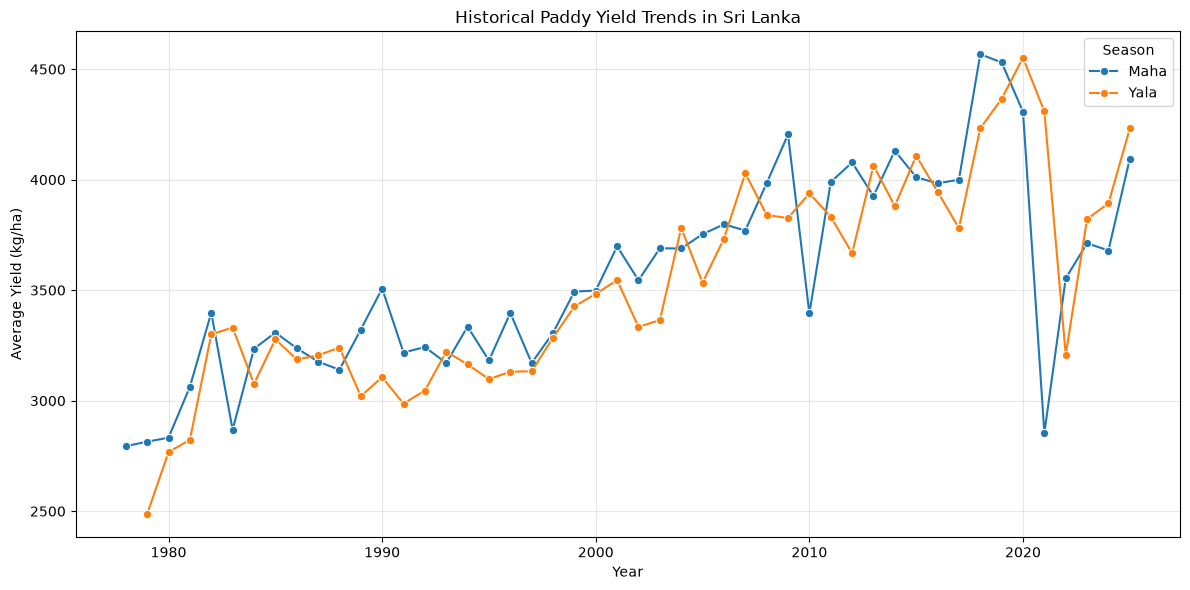

In [8]:
yearly_yield = (
    df.groupby(["year_start", "season"])["average_yield_kg_ha"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_yield,
    x="year_start",
    y="average_yield_kg_ha",
    hue="season",
    marker="o"
)

plt.title("Historical Paddy Yield Trends in Sri Lanka")
plt.xlabel("Year")
plt.ylabel("Average Yield (kg/ha)")
plt.legend(title="Season")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

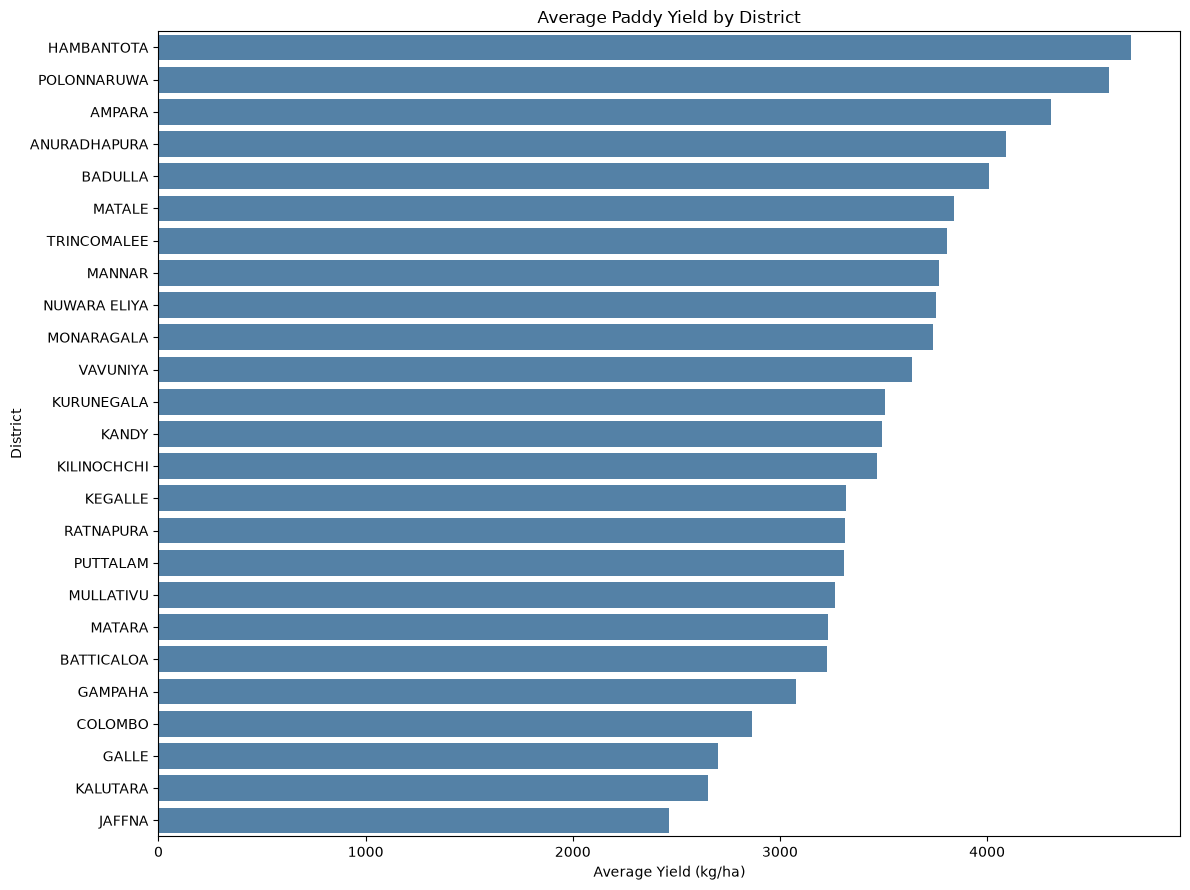

In [9]:
district_yield = (
    df.groupby("district")["average_yield_kg_ha"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=district_yield,
    x="average_yield_kg_ha",
    y="district",
    color="steelblue"
)

plt.title("Average Paddy Yield by District")
plt.xlabel("Average Yield (kg/ha)")
plt.ylabel("District")

plt.tight_layout()
plt.show()

In [10]:
print("Top 5 districts:")
print(district_yield.head(5))

print("\nBottom 5 districts:")
print(district_yield.tail(5))

Top 5 districts:
       district  average_yield_kg_ha
0    HAMBANTOTA          4696.489892
1   POLONNARUWA          4590.509298
2        AMPARA          4306.220546
3  ANURADHAPURA          4090.896810
4       BADULLA          4009.050644

Bottom 5 districts:
    district  average_yield_kg_ha
20   GAMPAHA          3077.812321
21   COLOMBO          2867.067857
22     GALLE          2701.601848
23  KALUTARA          2651.846165
24    JAFFNA          2465.820000


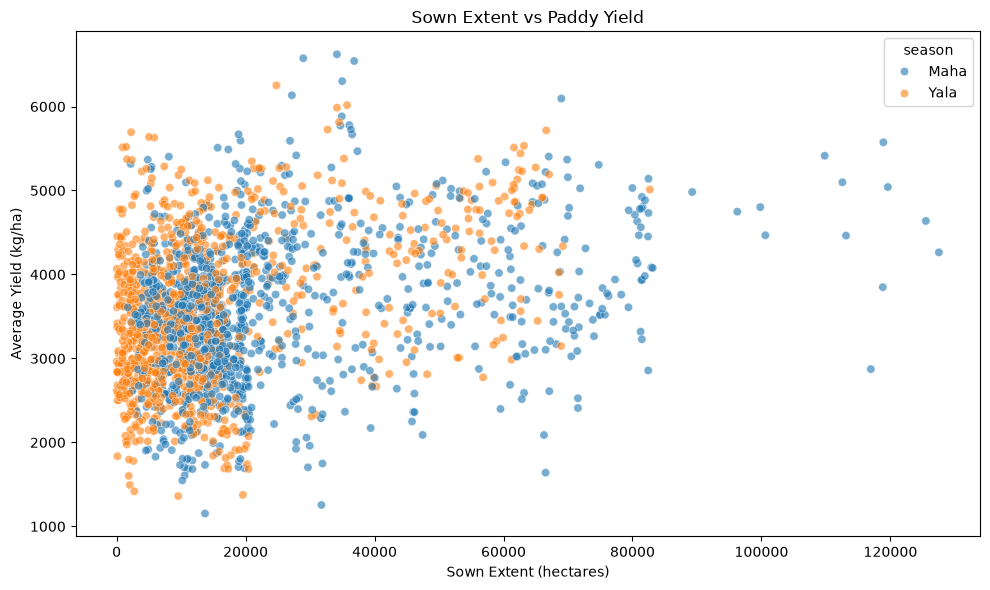

In [11]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="sown_extent_ha",
    y="average_yield_kg_ha",
    hue="season",
    alpha=0.6
)

plt.title("Sown Extent vs Paddy Yield")
plt.xlabel("Sown Extent (hectares)")
plt.ylabel("Average Yield (kg/ha)")

plt.tight_layout()
plt.show()

In [12]:
correlation = df[
    ["sown_extent_ha", "average_yield_kg_ha"]
].corr()

print(correlation)

                     sown_extent_ha  average_yield_kg_ha
sown_extent_ha             1.000000             0.318229
average_yield_kg_ha        0.318229             1.000000


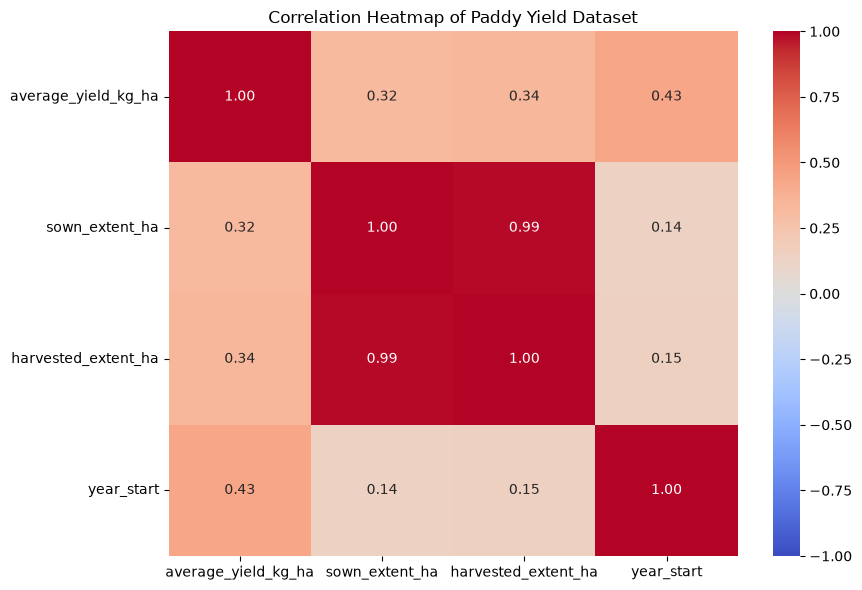

In [13]:
numeric_df = df[
    [
        "average_yield_kg_ha",
        "sown_extent_ha",
        "harvested_extent_ha",
        "year_start"
    ]
]

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Paddy Yield Dataset")
plt.tight_layout()
plt.show()
